In [1]:
import os
import SimpleITK as sitk
from collections import Counter

def check_dataset_shapes(images_dir):
    image_files = [f for f in os.listdir(images_dir) if f.endswith(".mha")]
    shapes = []

    for file in image_files:
        image_path = os.path.join(images_dir, file)
        image = sitk.ReadImage(image_path)
        array = sitk.GetArrayFromImage(image)  # [Z, H, W]
        
        # Sadece slice boyutları önemli (H, W)
        shapes.append(array.shape[1:])

    shape_counts = Counter(shapes)

    print("📊 Dataset içindeki slice boyut dağılımı:")
    for shape, count in shape_counts.items():
        print(f"Boyut: {shape}  →  {count} adet")

    return shape_counts


In [3]:
check_dataset_shapes(r"C:\Users\user\Desktop\TeethSegmentation\ToothFairy2_DataSet\imagesTr")

📊 Dataset içindeki slice boyut dağılımı:
Boyut: (512, 512)  →  10 adet
Boyut: (410, 410)  →  53 adet
Boyut: (352, 370)  →  3 adet
Boyut: (319, 370)  →  4 adet
Boyut: (301, 370)  →  2 adet
Boyut: (356, 371)  →  1 adet
Boyut: (334, 371)  →  2 adet
Boyut: (371, 370)  →  29 adet
Boyut: (309, 370)  →  3 adet
Boyut: (306, 370)  →  2 adet
Boyut: (289, 370)  →  2 adet
Boyut: (332, 462)  →  2 adet
Boyut: (279, 370)  →  1 adet
Boyut: (282, 371)  →  2 adet
Boyut: (337, 371)  →  3 adet
Boyut: (294, 370)  →  1 adet
Boyut: (370, 370)  →  34 adet
Boyut: (277, 370)  →  2 adet
Boyut: (265, 370)  →  1 adet
Boyut: (295, 370)  →  4 adet
Boyut: (324, 371)  →  1 adet
Boyut: (369, 370)  →  4 adet
Boyut: (283, 370)  →  1 adet
Boyut: (370, 371)  →  23 adet
Boyut: (341, 463)  →  1 adet
Boyut: (286, 370)  →  4 adet
Boyut: (371, 371)  →  15 adet
Boyut: (326, 371)  →  1 adet
Boyut: (397, 463)  →  1 adet
Boyut: (342, 370)  →  4 adet
Boyut: (300, 370)  →  3 adet
Boyut: (369, 371)  →  5 adet
Boyut: (285, 370)  →  1 a

Counter({(410, 410): 53,
         (370, 370): 34,
         (371, 370): 29,
         (370, 371): 23,
         (371, 371): 15,
         (512, 512): 10,
         (317, 370): 6,
         (369, 371): 5,
         (319, 370): 4,
         (295, 370): 4,
         (369, 370): 4,
         (286, 370): 4,
         (342, 370): 4,
         (324, 370): 4,
         (321, 370): 4,
         (352, 370): 3,
         (309, 370): 3,
         (337, 371): 3,
         (300, 370): 3,
         (379, 462): 3,
         (332, 370): 3,
         (336, 371): 3,
         (298, 371): 3,
         (299, 370): 3,
         (302, 370): 3,
         (338, 370): 3,
         (322, 370): 3,
         (362, 371): 3,
         (281, 370): 3,
         (315, 370): 3,
         (301, 370): 2,
         (334, 371): 2,
         (306, 370): 2,
         (289, 370): 2,
         (332, 462): 2,
         (282, 371): 2,
         (277, 370): 2,
         (371, 462): 2,
         (336, 463): 2,
         (310, 371): 2,
         (363, 462): 2,
         (

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

def show_sample(image_path, mask_path):
    # .npy dosyalarını oku
    image = np.load(image_path)
    mask = np.load(mask_path)

    print(f"📐 Image shape: {image.shape}")
    print(f"📐 Mask shape: {mask.shape}")

    # Görselleştir
    fig, axs = plt.subplots(1, 2, figsize=(12, 6))

    axs[0].imshow(image, cmap="gray")
    axs[0].set_title("Image Slice")
    axs[0].axis("off")

    axs[1].imshow(mask, cmap="nipy_spectral")
    axs[1].set_title("Mask Slice")
    axs[1].axis("off")

    plt.tight_layout()
    plt.show()

    print(f"🎯 Masked sınıflar: {np.unique(mask)}")

📐 Image shape: (410, 410)
📐 Mask shape: (410, 410)


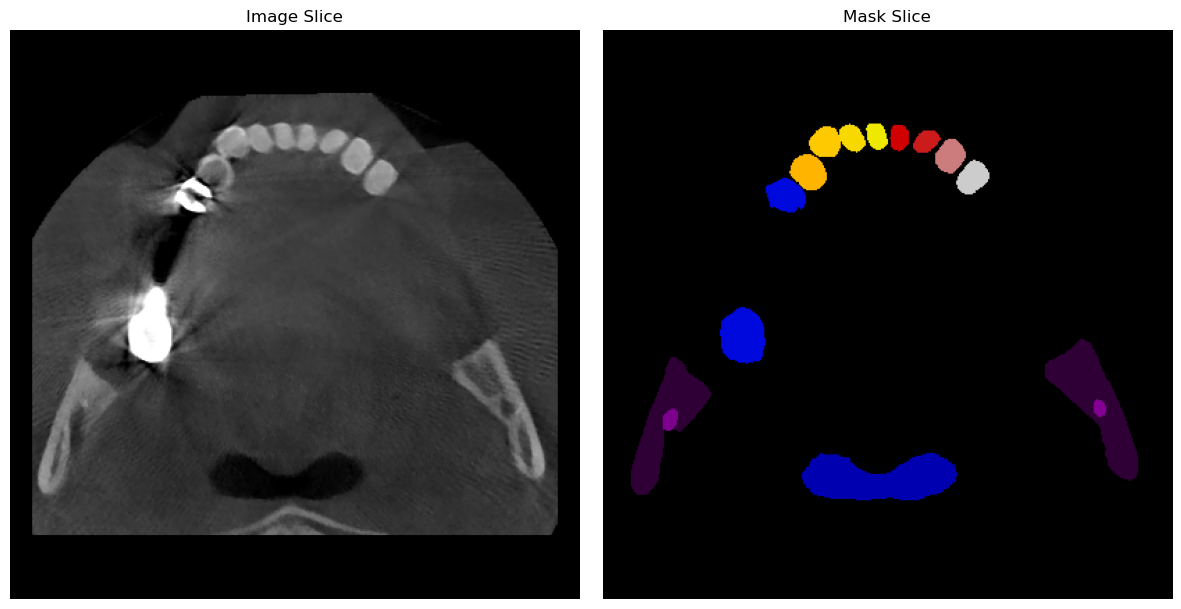

🎯 Masked sınıflar: [ 0  1  3  4  7  9 31 32 33 34 41 42 43 44]


In [25]:
show_sample(
    image_path=r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\train\images\ToothFairy2P_514_0000.npy",
    mask_path=r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\train\masks\ToothFairy2P_514_0000.npy"
)

In [17]:
import os
import numpy as np

def check_shapes(directory):
    shapes = []
    files = sorted(os.listdir(directory))
    for file in files:
        if file.endswith(".npy"):
            array = np.load(os.path.join(directory, file))
            shapes.append(array.shape)
    return shapes

train_image_shapes = check_shapes(r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\train\images")
train_mask_shapes = check_shapes(r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\train\masks")

print("Train image shapes:", set(train_image_shapes))
print("Train mask shapes:", set(train_mask_shapes))

Train image shapes: {(27, 410), (60, 410), (51, 410), (25, 410), (16, 410), (7, 410), (29, 410), (31, 410), (20, 410), (55, 410), (13, 410), (24, 410), (15, 410), (39, 410), (37, 410), (59, 410), (50, 410), (19, 410), (30, 410), (32, 410), (1, 410), (63, 410), (54, 410), (12, 410), (23, 410), (14, 410), (410, 410), (3, 410), (36, 410)}
Train mask shapes: {(27, 410), (60, 410), (51, 410), (25, 410), (16, 410), (7, 410), (29, 410), (31, 410), (20, 410), (55, 410), (13, 410), (24, 410), (15, 410), (39, 410), (37, 410), (59, 410), (50, 410), (19, 410), (30, 410), (32, 410), (1, 410), (63, 410), (54, 410), (12, 410), (23, 410), (14, 410), (410, 410), (3, 410), (36, 410)}
